# Modèle APT – mode asynchrone (Fig. 5c et Fig. 7b)

**Article :** Cosme, Thomas & Gaucherel (2023), *On the History of Ecosystem Dynamical Modeling: The Rise and Promises of Qualitative Models*, Entropy 25(11), 1526.

## Objectif
Reproduire sous `ecco` le modèle de désassemblage de communauté **APT** (section 4.1, Fig. 5) et son graphe de transitions d'états (STG) en **mode asynchrone**, le mode d'exécution d'EDEN (section 4.4, Fig. 7b).

## Le modèle
Trois espèces de protistes, issues des expériences de Weatherby et al. (1998) :

| Variable | Espèce |
|---|---|
| **A** | *Amoeba proteus* |
| **P** | *Paramecium caudatum* |
| **T** | *Tetrahymena pyriformis* |

Interactions : A mange P et dépend de lui ; A mange T ; P est en compétition (unidirectionnelle) avec T.

Chaque interaction devient une règle « si-alors » dont la réalisation est une **extinction** :

| Règle | Écriture | Lecture |
|---|---|---|
| R1 | `A+ >> P-` | si A est présent, P peut disparaître (prédation) |
| R2 | `A+ >> T-` | si A est présent, T peut disparaître (prédation) |
| R3 | `P+ >> T-` | si P est présent, T peut disparaître (compétition) |
| R4 | `P- >> A-` | si P a disparu, A peut disparaître (A dépend de P) |

Le fichier `APT.rr` contient exactement ces quatre règles. L'état initial est {APT} : les trois espèces sont présentes.

**Mode asynchrone :** les règles sont exécutées **une par une**, sans horloge globale. Chaque tir de règle est une transition, et toutes les trajectoires possibles sont calculées (approche *possibiliste*, section 4.5).

## 1. Chargement de la bibliothèque

In [1]:
import ecco
print("ECCO est disponible")

ECCO est disponible


## 2. Chargement du modèle
`ecco.load` lit le fichier `.rr` et renvoie le modèle. Appeler `model()` calcule tous les états accessibles depuis l'état initial {APT} (les `+` du fichier).

> Le fichier `APT.rr` doit être dans le même dossier que le notebook (dans le projet, une copie est rangée dans `modeles/`).

In [2]:
rr, model = ecco.load("APT.rr")

## 3. Calcul et affichage du graphe d'états
`model()` calcule **tous** les états atteignables depuis {APT} en exécutant les règles une par une. `explicit()` sépare le résultat en un nœud par état, et `draw()` affiche le STG obtenu.

> Sans `explicit()`, `model()` contient déjà les 6 états accessibles, mais regroupés en **une seule composante** : `draw()` renvoie alors l'erreur « cannot draw a graph with only one node ». `explicit()` sépare cette composante en un nœud par état.

In [3]:
graph = model()
graph = graph.explicit()
graph.draw()

## 4. Résultat attendu (Fig. 5c / 7b) et vérification

Le graphe affiché doit avoir **6 états** et **6 transitions** :

| Transition | Règle(s) | Remarque |
|---|---|---|
| APT → AT | R1 | P s'éteint |
| APT → AP | R2 ou R3 | T s'éteint, deux règles possibles |
| AT → T | R4 | A s'éteint car P est absent |
| AT → A | R2 | T s'éteint |
| AP → A | R1 | P s'éteint |
| A → ∅ | R4 | A s'éteint car P est absent |

**À cocher en comparant avec le graphe affiché :**
- [x] 6 états : APT, AT, AP, A, T, ∅ ;
- [x] mêmes arêtes et mêmes étiquettes de règles que la Fig. 5c ;
- [x] deux états sans successeur (états stables) : **{T}** et **{∅}**.

**Lecture du graphe obtenu dans ecco** (capture `figures/ecco_asynchrone.png`). ecco numérote les états ; ▶ marque l'état initial et ■ un état stable (`DEAD`). On identifie chaque numéro grâce aux règles sur les arcs (l'onglet *Nodes* donne aussi la valeur de chaque variable) :

| N° ecco | État | Arrivée par |
|---|---|---|
| 6 ▶ | APT | état initial |
| 5 | AT | R1 |
| 3 | AP | R2, R3 |
| 2 | A | R2 (depuis 5) ou R1 (depuis 3) |
| 4 ■ | {T} | R4 |
| 1 ■ | ∅ | R4 |

Le graphe calculé par ecco est donc identique à la Fig. 5c.

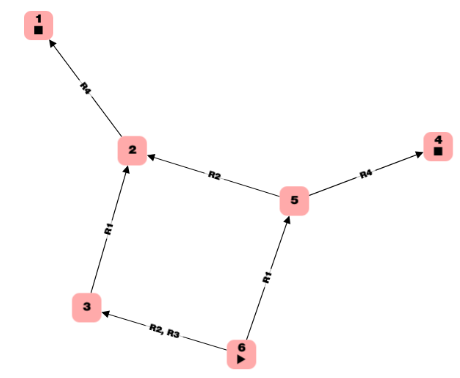

*Capture de la sortie de `draw()` ci-dessus, jointe ici car le widget interactif ne s'affiche pas quand le notebook est ouvert en dehors de Jupyter.*

## 5. Interprétation

- Depuis {APT}, le modèle prédit **trois trajectoires distinctes** d'extinction, et **deux états finaux** : {T} et {∅}.
- D'après l'article, ces états sont **observés expérimentalement** (Weatherby et al., 1998 ; de Goër de Herve et al., prépublication). Le mode asynchrone reproduit donc le comportement observé, y compris l'état {T}.
- L'article en tire l'explication suivante : *« l'extinction de P est une condition nécessaire mais non suffisante pour que {T} persiste »*. Pour atteindre {T}, il faut que P s'éteigne d'abord (R1, état AT), puis que A disparaisse faute de P (R4) **avant** d'avoir mangé T (R2). Depuis AT, R3 ne s'applique plus, car P est absent. Si T s'éteint en premier (R2 ou R3, état AP), ou si R2 passe avant R4, on arrive à {∅}.
- Le STG fournit ainsi une **explication historique** (quelle séquence d'extinctions mène à quel état final) sans aucune valeur numérique ni probabilité.

➡️ Pour voir pourquoi le mode d'exécution compte, voir le notebook `APT_synchrone (1).ipynb` (Fig. 7a), qui n'atteint jamais {T}.